# ARTI 402 — Deep Learning

## Lab 10 — Attention: Letting the Network Look Back

### Read and reference

### How to work through the notebook

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)
LEARN = '#E8A33D'
FIXED = '#8FB8D6'
EDGE = '#333333'
OUTC = '#F3D9B1'

def draw_bottleneck_vs_attention(T=6):
    fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.3))
    xs = np.linspace(0.7, 5.3, T)
    for ax, mode in zip(axes, ('bottleneck', 'attention')):
        for i, x in enumerate(xs):
            ax.add_patch(plt.Rectangle((x - 0.26, -0.32), 0.52, 0.64, facecolor=LEARN, edgecolor=EDGE, lw=1.2, zorder=4))
            ax.text(x, 0, f'h{i + 1}', ha='center', va='center', fontsize=8.5, zorder=6)
        for x0, x1 in zip(xs[:-1], xs[1:]):
            ax.annotate('', xy=(x1 - 0.29, 0), xytext=(x0 + 0.29, 0), arrowprops=dict(arrowstyle='-|>', color='#777', lw=1.2))
        ax.add_patch(plt.Rectangle((2.6, 2.0), 1.0, 0.72, facecolor=FIXED, edgecolor=EDGE, lw=1.4, zorder=4))
        ax.text(3.1, 2.36, 'output', ha='center', va='center', fontsize=9.5, weight='bold', zorder=6)
        if mode == 'bottleneck':
            ax.annotate('', xy=(3.1, 1.96), xytext=(xs[-1], 0.36), arrowprops=dict(arrowstyle='-|>', color='#C0392B', lw=2.4))
            ax.text(4.9, 1.25, 'only the LAST\nhidden state', fontsize=9.3, color='#C0392B', weight='bold', ha='center')
            ax.set_title('Lab 4: one vector carries everything', fontsize=11.5, weight='bold')
            for x in xs[:-1]:
                ax.plot([x, x], [0.36, 0.7], color='#BBB', lw=1, ls=':')
        else:
            for i, x in enumerate(xs):
                lw = 2.6 if i == 1 else 1.0
                col = '#C0392B' if i == 1 else '#9AA5B1'
                ax.annotate('', xy=(3.1, 1.96), xytext=(x, 0.36), arrowprops=dict(arrowstyle='-|>', color=col, lw=lw, alpha=1.0 if i == 1 else 0.75))
            ax.text(4.9, 1.25, 'looks at ALL of them,\nweighted', fontsize=9.3, color='#B5651D', weight='bold', ha='center')
            ax.set_title('Today: every step stays reachable', fontsize=11.5, weight='bold')
        ax.set_xlim(0, 6.3)
        ax.set_ylim(-1.0, 3.0)
        ax.axis('off')
    plt.tight_layout()
    return fig

def draw_attention_heatmap(weights, row_labels=None, col_labels=None, title='Attention weights', annotate=True):
    W = np.asarray(weights)
    nq, nk = W.shape
    fig, ax = plt.subplots(figsize=(min(1.0 * nk + 2.4, 11), min(0.78 * nq + 2.0, 9)))
    im = ax.imshow(W, cmap='Oranges', vmin=0, vmax=max(W.max(), 1e-09), aspect='auto', interpolation='nearest')
    ax.set_xticks(range(nk))
    ax.set_yticks(range(nq))
    ax.set_xticklabels(col_labels if col_labels is not None else range(nk), fontsize=9)
    ax.set_yticklabels(row_labels if row_labels is not None else range(nq), fontsize=9)
    ax.set_xlabel('attending TO  (keys)')
    ax.set_ylabel('attending FROM  (queries)')
    if annotate and nq * nk <= 90:
        for i in range(nq):
            for j in range(nk):
                ax.text(j, i, f'{W[i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if W[i, j] > W.max() * 0.6 else '#333')
    fig.colorbar(im, ax=ax, shrink=0.85, label='weight')
    ax.set_title(title, fontsize=12.5, weight='bold')
    plt.tight_layout()
    return fig

def draw_qkv_mechanism():
    fig, ax = plt.subplots(figsize=(11.5, 4.6))
    ax.add_patch(plt.Rectangle((0.3, 1.5), 1.5, 0.8, facecolor=FIXED, edgecolor=EDGE, lw=1.4, zorder=4))
    ax.text(1.05, 1.9, 'QUERY', ha='center', va='center', fontsize=10.5, weight='bold', zorder=6)
    ax.text(1.05, 1.15, 'what am I\nlooking for?', ha='center', va='top', fontsize=8.8)
    ys = [3.1, 2.3, 1.5, 0.7]
    for i, y in enumerate(ys):
        ax.add_patch(plt.Rectangle((3.3, y - 0.3), 1.1, 0.6, facecolor=LEARN, edgecolor=EDGE, lw=1.2, zorder=4))
        ax.text(3.85, y, f'key {i + 1}', ha='center', va='center', fontsize=8.6, zorder=6)
        ax.add_patch(plt.Rectangle((5.9, y - 0.3), 1.3, 0.6, facecolor=OUTC, edgecolor=EDGE, lw=1.2, zorder=4))
        ax.text(6.55, y, f'value {i + 1}', ha='center', va='center', fontsize=8.6, zorder=6)
        ax.annotate('', xy=(3.26, y), xytext=(1.85, 1.9), arrowprops=dict(arrowstyle='-|>', color='#999', lw=1.1))
    ax.text(3.85, 3.75, 'KEYS', ha='center', fontsize=10.5, weight='bold')
    ax.text(3.85, 3.5, 'labels on the shelf', ha='center', fontsize=8.6)
    ax.text(6.55, 3.75, 'VALUES', ha='center', fontsize=10.5, weight='bold')
    ax.text(6.55, 3.5, 'the actual contents', ha='center', fontsize=8.6)
    ax.text(2.55, 3.15, 'compare\n(dot product)', ha='center', fontsize=8.8, style='italic', color='#555')
    ax.annotate('', xy=(5.86, 2.3), xytext=(4.46, 2.3), arrowprops=dict(arrowstyle='-|>', color='#B5651D', lw=2.2))
    ax.text(5.16, 2.52, 'softmax\nweights', ha='center', fontsize=8.6, color='#B5651D', weight='bold')
    ax.add_patch(plt.Rectangle((8.5, 1.5), 1.8, 0.8, facecolor=FIXED, edgecolor=EDGE, lw=1.4, zorder=4))
    ax.text(9.4, 1.9, 'OUTPUT', ha='center', va='center', fontsize=10.5, weight='bold', zorder=6)
    ax.text(9.4, 1.15, 'a weighted blend\nof the values', ha='center', va='top', fontsize=8.8)
    for y in ys:
        ax.annotate('', xy=(8.46, 1.9), xytext=(7.26, y), arrowprops=dict(arrowstyle='-|>', color='#999', lw=1.1))
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 4.3)
    ax.axis('off')
    ax.set_title('Query, Keys, Values  —  a soft lookup table', fontsize=12.5, weight='bold', pad=10)
    plt.tight_layout()
    return fig

def draw_length_sweep(lengths, series, title='Accuracy as the sequence gets longer', chance=None):
    fig, ax = plt.subplots(figsize=(7.8, 4.5))
    markers = ['o-', 's--', '^-.', 'd:']
    for (name, vals), m in zip(series.items(), markers):
        ax.plot(lengths, vals, m, lw=2, ms=6, label=name)
    if chance is not None:
        ax.axhline(chance, color='grey', ls=':', lw=1.3, label='chance')
    ax.set_xscale('log', base=2)
    ax.set_xticks(lengths)
    ax.set_xticklabels([str(t) for t in lengths])
    ax.set_xlabel('sequence length')
    ax.set_ylabel('test accuracy')
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    ax.set_title(title, fontsize=12.5, weight='bold')
    plt.tight_layout()
    return fig
print('Setup OK - NumPy', np.__version__)

Setup OK - NumPy 2.5.4


# Stage 1 · The problem you already met

## One vector is not enough

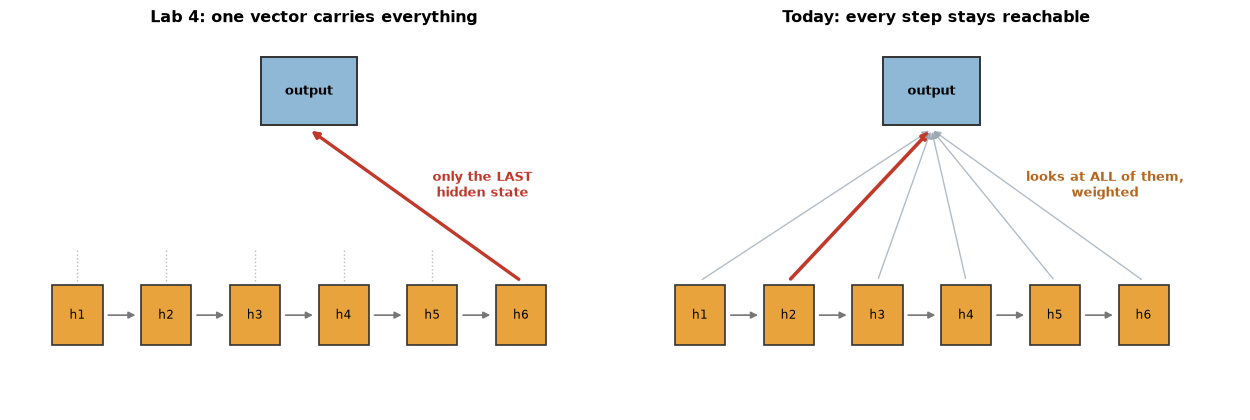

In [2]:
draw_bottleneck_vs_attention(T=6)
plt.show()

# Stage 2 · Query, Key, Value

## A lookup table that blurs

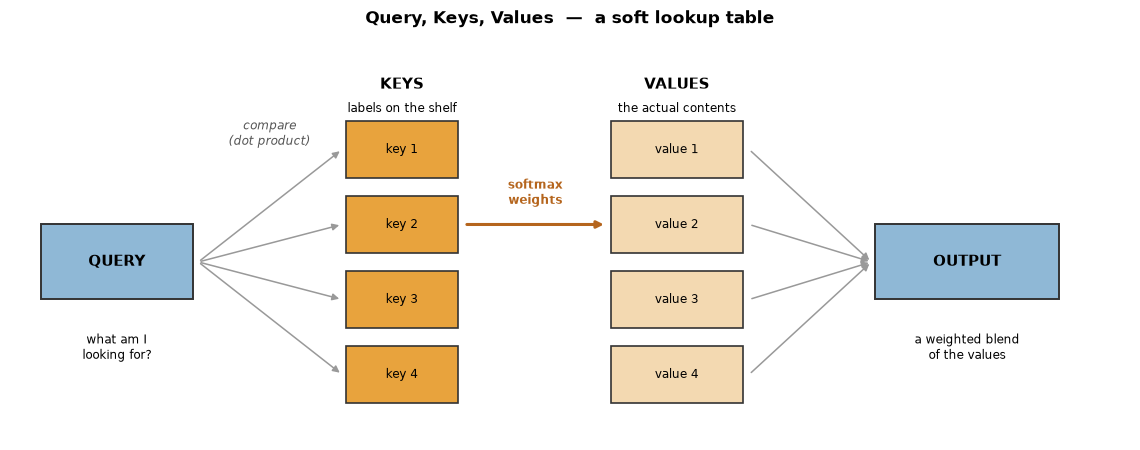

In [3]:
draw_qkv_mechanism()
plt.show()

### Exercise 1 — write it

In [4]:
def softmax(x, axis=-1):
    e = np.exp(x - x.max(axis=axis, keepdims=True))
    return e / e.sum(axis=axis, keepdims=True)

def attention(Q, K, V, mask=None):
    d_k = K.shape[-1]
    scores = Q @ K.T / np.sqrt(d_k)
    if mask is not None:
        mask = np.broadcast_to(np.asarray(mask, dtype=bool), scores.shape)
        if not np.all(mask.any(axis=-1)):
            raise ValueError('Each query must have at least one allowed key.')
        scores = np.where(mask, scores, -np.inf)
    weights = softmax(scores, axis=-1)
    output = weights @ V
    return (output, weights)
Qc = np.array([[1.0, 0.0]])
Kc = np.array([[1.0, 0.0], [0.0, 1.0]])
Vc = np.array([[10.0], [20.0]])
o, w = attention(Qc, Kc, Vc)
assert w.shape == (1, 2), 'one weight per key, per query'
assert np.allclose(w.sum(axis=1), 1.0), 'each row of weights must sum to 1'
assert o.shape == (1, 1), 'output is a blend of the values'
assert o[0, 0] < 15, 'the query matches key 1, so the output should lean towards 10'
print('attention() works')
print('weights:', w[0], '  output:', o[0])

attention() works
weights: [0.67 0.33]   output: [13.302]


### Exercise 2 — a lookup table you can check by hand

In [5]:
K = np.eye(4)
V = np.array([[10.0, 0.0], [20.0, 1.0], [30.0, 2.0], [40.0, 3.0]])
q_exact = np.array([[0.0, 1.0, 0.0, 0.0]])
out, w = attention(q_exact, K, V)
print(f'exact query      weights {w[0]}  output {out[0]}')
q_sharp = q_exact * 5
out, w = attention(q_sharp, K, V)
print(f'5x sharper       weights {w[0]}  output {out[0]}')
q_split = np.array([[3.0, 3.0, 0.0, 0.0]])
out, w = attention(q_split, K, V)
print(f'torn 1 and 2     weights {w[0]}  output {out[0]}')
print('The split query gives equal weight to slots 1 and 2, with some weight still on slots 3 and 4.')

exact query      weights [0.215 0.355 0.215 0.215]  output [24.302  1.43 ]
5x sharper       weights [0.066 0.802 0.066 0.066]  output [21.317  1.132]
torn 1 and 2     weights [0.409 0.409 0.091 0.091]  output [18.649  0.865]
The split query gives equal weight to slots 1 and 2, with some weight still on slots 3 and 4.


# Stage 3 · Why divide by $\sqrt{d_k}$

## The quietest line in the formula

### Exercise 3 — measure it

In [6]:
rng = np.random.RandomState(0)
print(f"{'d_k':>6}{'raw score range':>26}{'max weight raw':>17}{'max weight scaled':>20}")
for d in [4, 64, 512]:
    q = rng.randn(1, d)
    k = rng.randn(6, d)
    raw = (q @ k.T)[0]
    scaled = raw / np.sqrt(d)
    print(f'{d:6d}   {raw.min():9.2f} to {raw.max():7.2f}{softmax(raw).max():17.3f}{softmax(scaled).max():20.3f}')
print('Large unscaled scores can saturate softmax and make gradients very small; scaling reduces this effect.')

   d_k           raw score range   max weight raw   max weight scaled
     4       -5.06 to    3.49            0.332               0.272
    64      -11.37 to    4.99            0.969               0.320
   512      -24.36 to   11.33            1.000               0.300
Large unscaled scores can saturate softmax and make gradients very small; scaling reduces this effect.


# Stage 4 · Attention beats the bottleneck

## A fair fight, with no training at all

### Exercise 4 — run the sweep

In [7]:
def retrieval_trial(T, d=16, rng=None):
    if rng is None:
        rng = np.random.RandomState(0)
    K = rng.randn(T, d)
    V = rng.randn(T, d)
    i = rng.randint(T)
    q = K[i:i + 1] * 4.0
    out_attn, _ = attention(q, K, V)
    summary = V.mean(axis=0, keepdims=True)
    pick_attn = int(np.argmin(((V - out_attn) ** 2).sum(axis=1)))
    pick_bott = int(np.argmin(((V - summary) ** 2).sum(axis=1)))
    return (pick_attn == i, pick_bott == i)
rng = np.random.RandomState(0)
lengths = [2, 4, 8, 16, 32, 64]
acc_attention, acc_bottleneck = ([], [])
for T in lengths:
    hits_a = hits_b = 0
    trials = 400
    for _ in range(trials):
        ha, hb = retrieval_trial(T, rng=rng)
        hits_a += ha
        hits_b += hb
    acc_attention.append(hits_a / trials)
    acc_bottleneck.append(hits_b / trials)
    print(f'T = {T:3d}   attention {hits_a / trials:.3f}   bottleneck {hits_b / trials:.3f}   chance {1 / T:.3f}')
assert acc_attention[-1] > 0.85, 'attention should barely care about length'
assert acc_bottleneck[-1] < 0.1, 'the bottleneck should collapse towards chance'

T =   2   attention 1.000   bottleneck 0.430   chance 0.500
T =   4   attention 0.993   bottleneck 0.225   chance 0.250


T =   8   attention 0.990   bottleneck 0.135   chance 0.125
T =  16   attention 0.990   bottleneck 0.050   chance 0.062


T =  32   attention 0.980   bottleneck 0.035   chance 0.031


T =  64   attention 0.958   bottleneck 0.015   chance 0.016


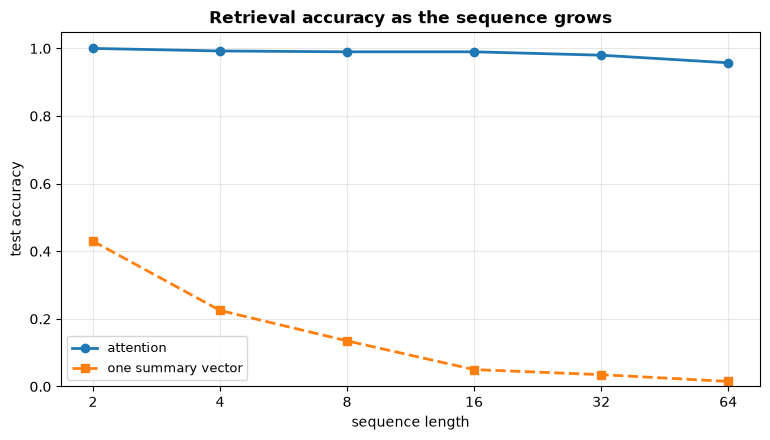

In [8]:
draw_length_sweep(lengths, {'attention': acc_attention, 'one summary vector': acc_bottleneck}, title='Retrieval accuracy as the sequence grows')
plt.show()

# Stage 5 · Self-attention

## When the sequence looks at itself

### Exercise 5 — self-attention on a sentence

sequence: (6, 8)  (6 words, 8 numbers each)

every row sums to 1: True


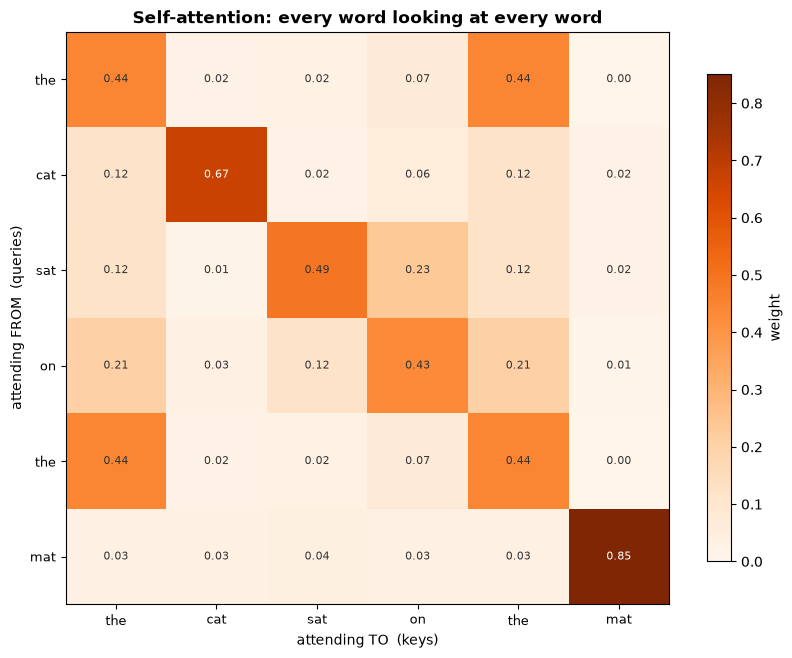

In [9]:
words = ['the', 'cat', 'sat', 'on', 'the', 'mat']
rng2 = np.random.RandomState(3)
d = 8
vocab = {w: rng2.randn(d) for w in sorted(set(words))}
X = np.array([vocab[w] for w in words])
print('sequence:', X.shape, ' (6 words, 8 numbers each)')
out, W = attention(X, X, X)
print('\nevery row sums to 1:', np.allclose(W.sum(axis=1), 1.0))
draw_attention_heatmap(W, row_labels=words, col_labels=words, title='Self-attention: every word looking at every word')
plt.show()
assert W.shape == (6, 6), '6 words attending to 6 words'
assert out.shape == X.shape, 'each position is rebuilt, same shape'

In [10]:
print("row for 'the' at position 0 :", W[0])
print("row for 'the' at position 4 :", W[4])
print('identical?', np.allclose(W[0], W[4]))

row for 'the' at position 0 : [0.443 0.018 0.022 0.072 0.443 0.002]
row for 'the' at position 4 : [0.443 0.018 0.022 0.072 0.443 0.002]
identical? True


### Idea 6 — Multi-head attention, in one paragraph

# Assessment

## Q1 — Masking, and how GPT works

the mask (True = allowed):
[[1 0 0 0 0]
 [1 1 0 0 0]
 [1 1 1 0 0]
 [1 1 1 1 0]
 [1 1 1 1 1]]

causal attention weights:
[[1.    0.    0.    0.    0.   ]
 [0.423 0.577 0.    0.    0.   ]
 [0.273 0.247 0.48  0.    0.   ]
 [0.089 0.113 0.039 0.758 0.   ]
 [0.236 0.177 0.153 0.076 0.358]]


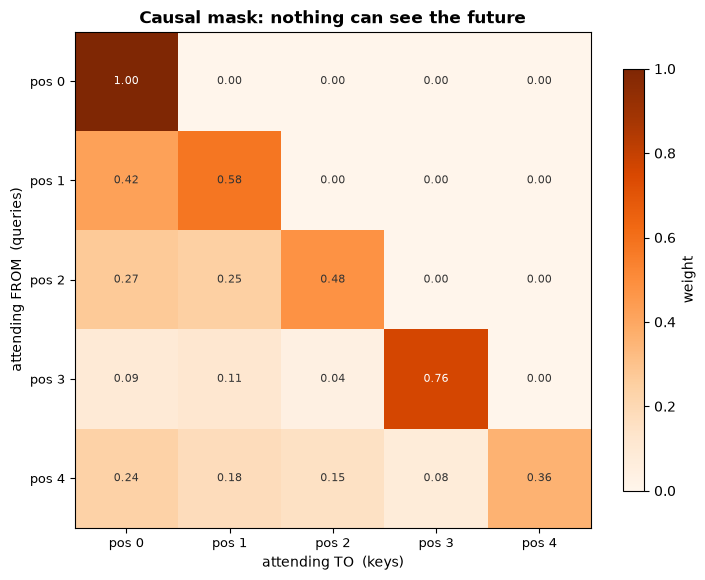

In [11]:
T = 5
causal = np.tril(np.ones((T, T), dtype=bool))
print('the mask (True = allowed):')
print(causal.astype(int))
rng3 = np.random.RandomState(1)
Xc = rng3.randn(T, 6)
out_c, W_c = attention(Xc, Xc, Xc, mask=causal)
print('\ncausal attention weights:')
print(W_c)
draw_attention_heatmap(W_c, row_labels=[f'pos {i}' for i in range(T)], col_labels=[f'pos {i}' for i in range(T)], title='Causal mask: nothing can see the future')
plt.show()
assert np.allclose(np.triu(W_c, 1), 0), 'nothing above the diagonal may have weight'
assert np.allclose(W_c.sum(axis=1), 1.0), 'rows must still sum to 1'
assert np.allclose(W_c[0], [1, 0, 0, 0, 0]), 'position 0 can only see itself'

### Q1 Answer

`W_c[0] = [1, 0, 0, 0, 0]` because position 0 can attend only to itself.

## Q2 — What the mask costs

In [12]:
_, W_free = attention(Xc, Xc, Xc)
print(f"{'position':>10}{'keys visible':>15}{'self, unmasked':>18}{'self, masked':>16}")
for i in range(T):
    visible = int(causal[i].sum())
    self_free = W_free[i, i]
    self_mask = W_c[i, i]
    print(f'{i:10d}{visible:15d}{self_free:18.3f}{self_mask:16.3f}')

  position   keys visible    self, unmasked    self, masked
         0              1             0.585           1.000
         1              2             0.556           0.577
         2              3             0.412           0.480
         3              4             0.695           0.758
         4              5             0.358           0.358


### Q2 Results

| Position | Keys visible | Self unmasked | Self masked |
|---|---|---|---|
| 0 | 1 | 0.585 | 1.000 |
| 1 | 2 | 0.556 | 0.577 |
| 2 | 3 | 0.412 | 0.480 |
| 3 | 4 | 0.695 | 0.758 |
| 4 | 5 | 0.358 | 0.358 |

Masking removes future context and renormalizes allowed weights; self-attention increases or stays unchanged. A dense masked implementation still computes a full score matrix.

## Submission

## Verification

In [13]:
assert np.allclose(W[0], W[4])
assert np.all(np.isfinite(W_c))
assert np.count_nonzero(np.triu(W_c, 1)) == 0
assert np.all(np.diag(W_c) >= np.diag(W_free) - 1e-12)
assert np.allclose(W_c[-1], W_free[-1])
assert np.allclose(out_c[0], Xc[0])
assert np.allclose(softmax(np.array([10000.0, 10001.0])), softmax(np.array([0.0, 1.0])))
try:
    attention(np.ones((1, 2)), np.ones((2, 2)), np.ones((2, 1)), mask=np.zeros((1, 2), dtype=bool))
except ValueError:
    pass
else:
    raise AssertionError('Fully masked query should be rejected.')
print('All attention, masking, numerical and original exercise checks passed.')

All attention, masking, numerical and original exercise checks passed.
